# Step 6: backtest of all the agent variants (train only)

**Question.** Do the news improve the pairs-trading strategy? Version **A** (every signal enters) is compared with the variants of the news agent: **B** can block a trade, **C** can also follow the news (enter in the opposite direction). The code of the variants is in [agent_variants/](agent_variants/README.md), the engine in [backtest.py](backtest.py), the comparison functions in [agent_variants/comparison.py](agent_variants/comparison.py).

**Rules fixed before the results.** 10,000 dollars per leg, no leverage, everything closed at the end of the day; capital of 20,000 dollars per pair (300,000 in total); a trade has 4 operations. Main scenario: **cost 0** (the professor's indication); 5 basis points per operation is the realistic scenario.

**Train only** (16 June - 16 September 2026, 64 days). The test was not read: it is used only once, at the end, for the variant chosen with a criterion fixed beforehand. The robustness checks are in Step 7, [07_robustness.ipynb](07_robustness.ipynb).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # project folder: makes src importable

import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS
from src.backtest import (load_trades, trading_days, apply_version, add_costs, daily_pnl, summary, by_cost, by_group, breakeven_cost,
                          entry_window, version_trades, load_version, available_versions, version_file, save_results, VERSIONS, MAIN_COST)
from src.agent_variants.comparison import (references, all_variants, listing, compare, evaluate_blocks, evaluate_follows,
                                           same_as_reference, by_variant)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 220
trades, days = load_trades(), trading_days()          # load_trades refuses any trade after 16 September: train only
ref = references(trades)                              # A, A delayed by 5 and by 15 minutes
variants = all_variants(trades)
A = ref["A"]
assert len(A) == 973 and round(A.gross_bps.mean(), 1) == 7.4, "A does not match Step 4"
print(f"{len(A)} trades, {len(days)} train days ({days.min():%d/%m} - {days.max():%d/%m}), {A.pair.nunique()} pairs, {len(variants)} variants")

973 trades, 64 train days (16/06 - 16/09), 15 pairs, 21 variants


## 1. Version A, no agent

The reference of all the variants. Per cost, where the profit comes from (pair, entry time, exit reason) and how much it costs to enter 5 or 15 minutes after the signal (delayed A, the reference of the variants with a delayed entry).

In [2]:
t = by_cost(A, days)
t.assign(total_return_pct=100 * t.total_return, max_drawdown_pct=100 * t.max_drawdown)[
    ["trade", "gross_bps", "net_bps", "win_rate", "profit_factor", "pnl_usd", "total_return_pct", "sharpe", "max_drawdown_pct"]]

,trade,gross_bps,net_bps,win_rate,profit_factor,pnl_usd,total_return_pct,sharpe,max_drawdown_pct
cost_bps_per_operation,,,,,,,,,
0,973.00,7.44,7.44,0.60,1.45,"7,239.43",2.41,8.13,-0.15
2,973.00,7.44,-0.56,0.53,0.97,-544.57,-0.18,-0.62,-0.60
5,973.00,7.44,-12.56,0.39,0.52,"-12,220.57",-4.07,-13.55,-4.07
10,973.00,7.44,-32.56,0.20,0.20,"-31,680.57",-10.56,-31.28,-10.56


In [3]:
print(f"Break-even cost: {breakeven_cost(A):.2f} basis points per operation")
by_group(A, "pair", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]].sort_values("gross_bps", ascending=False)

Break-even cost: 1.86 basis points per operation


,trade,gross_bps,se_bps,win_rate
pair,,,,
PYPL-XYZ,60,29.60,13.98,0.63
CRM-WDAY,60,28.19,19.11,0.60
ELV-UNH,59,10.76,7.36,0.58
GS-MS,72,9.62,4.08,0.65
MA-V,75,7.54,2.51,0.64
CSX-UNP,61,6.81,4.16,0.56
CL-PG,63,6.61,4.73,0.60
DHR-TMO,62,6.59,6.46,0.58
HD-LOW,65,4.39,4.13,0.68


In [4]:
display(by_group(A, entry_window(A), cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]])
by_group(A, "exit_reason", cost_bps=0)[["trade", "gross_bps", "se_bps", "win_rate"]]

,trade,gross_bps,se_bps,win_rate
window,,,,
after 30 min,516,3.90,2.60,0.60
open (15-30 min),457,11.43,3.16,0.61


,trade,gross_bps,se_bps,win_rate
exit_reason,,,,
end_of_day,56,0.26,18.24,0.23
reversion,464,38.79,1.39,0.99
stop,31,-32.10,6.77,0.16
time,422,-23.17,2.92,0.26


In [5]:
t = pd.DataFrame({(name, c): summary(add_costs(t, c), days) for name, t in ref.items() for c in (0, MAIN_COST)}).T.rename_axis(["reference", "cost_bps"])
t.assign(max_drawdown_pct=100 * t.max_drawdown.astype(float))[["trade", "net_bps", "win_rate", "pnl_usd", "sharpe", "max_drawdown_pct"]]

trade  net_bps  win_rate    pnl_usd  sharpe  max_drawdown_pct
reference cost_bps                                                               
A         0        973.00     7.44      0.60   7,239.43    8.13             -0.15
          5        973.00   -12.56      0.39 -12,220.57  -13.55             -4.07
A_5min    0        964.00     5.26      0.59   5,071.41    6.08             -0.16
          5        964.00   -14.74      0.36 -14,208.59  -16.71             -4.74
A_15min   0        941.00     7.18      0.63   6,751.98    6.75             -0.14
          5        941.00   -12.82      0.36 -12,068.02  -12.26             -4.02

## 2. The variants

One row per variant and version. The reference is A, or the delayed A for the variants that decide and enter 5 or 15 minutes after the signal. `rule_before` = False: the rule was built by looking at the train results, so it does well there almost by necessity. The full rules are in [agent_variants/README.md](agent_variants/README.md) and in the [log](agent_variants/LOG.md).

Not shown: `ma_rules` (on the train it blocks nothing, it coincides with A) and the two sets on the 40 signals of the hand-classified sample, which are not compared on the whole portfolio.

In [6]:
listing(variants)

reference  rule_before                                        description
variant             version                                                                            
spark_24h           B                 A         True  Spark X2.6 4B agent, news of the previous 24 h...
                    C                 A         True  Spark X2.6 4B agent, news of the previous 24 h...
spark_6h            B                 A         True  Spark X2.6 4B agent, news of the previous 6 ho...
                    C                 A         True  Spark X2.6 4B agent, news of the previous 6 ho...
lexicon             B                 A         True  Baseline without a model: positive and negativ...
                    C                 A         True  Baseline without a model: positive and negativ...
3b_6h               B                 A         True  Llama 3.2 3B agent, news of the previous 6 hou...
finbert_session     B                 A         True  FinBERT on targeted news, window tied to the s...
                    C                 A         True  FinBERT on targeted news, window tied to the s...
c_fresh             C                 A         True  C only: follows fresh news (60 minutes, in ses...
finbert_episode     B                 A         True  FinBERT, rules of finbert_session with the new...
                    C                 A         True  FinBERT, rules of finbert_session with the new...
spark24h_agent_size B reduced         A         True  spark_24h: half size when the agent flags nois...
spark24h_block_half B reduced         A         True          spark_24h: half size instead of the block
3b_half             B reduced         A         True  3b_6h: half size instead of the block and when...
finbert_strong_half B reduced         A         True  FinBERT: half size with at least one targeted ...
finbert_delay_5min  B            A_5min         True  Rules of finbert_episode, decision and entry 5...
                    C            A_5min         True  Rules of finbert_episode, decision and entry 5...
finbert_delay_15min B           A_15min         True  Rules of finbert_episode, decision and entry 1...
                    C           A_15min         True  Rules of finbert_episode, decision and entry 1...
b_exaggeration      B                 A        False  spark_24h that enters when the news confirms t...

## 3. Comparison

Sorted from the best variant to the worst by the **dollar profit at cost 0 relative to its reference** (`delta_pnl_usd`), the criterion chosen by the group. Cost 5 as a comparison.

In [7]:
cmp = compare(variants, ref, days, costs=(0, MAIN_COST))
cmp[["reference", "rule_before", "trade", "net_bps", "pnl_usd", "delta_pnl_usd", "sharpe", "delta_sharpe", "max_drawdown_pct"]]

reference  rule_before  trade  net_bps    pnl_usd  delta_pnl_usd  sharpe  delta_sharpe  max_drawdown_pct
variant             version   cost_bps                                                                                                         
b_exaggeration      B         0                A        False    938     8.04   7,539.24         299.81    8.30          0.18             -0.16
                              5                A        False    938   -11.96 -11,220.76         999.81  -12.23          1.32             -3.74
c_fresh             C         0                A         True    973     7.44   7,239.43          -0.00    8.13          0.00             -0.15
                              5                A         True    973   -12.56 -12,220.57           0.00  -13.55          0.00             -4.07
finbert_delay_15min B         0          A_15min         True    935     7.15   6,689.12         -62.86    6.85          0.09             -0.14
                              5          A_15min         True    935   -12.85 -12,010.88          57.14  -12.73         -0.47             -4.00
finbert_delay_5min  B         0           A_5min         True    960     5.20   4,996.14         -75.27    6.01         -0.08             -0.16
                              5           A_5min         True    960   -14.80 -14,203.86           4.73  -17.07         -0.36             -4.73
finbert_episode     B         0                A         True    968     7.18   6,954.50        -284.92    8.13          0.01             -0.14
                              5                A         True    968   -12.82 -12,405.50        -184.92  -14.62         -1.07             -4.14
3b_half             B reduced 0                A         True    973     7.14   6,817.60        -421.83    7.93         -0.20             -0.13
                              5                A         True    973   -12.86 -12,292.40         -71.83  -14.22         -0.67             -4.10
finbert_session     B         0                A         True    964     7.02   6,770.36        -469.07    7.99         -0.14             -0.14
                              5                A         True    964   -12.98 -12,509.64        -289.07  -14.77         -1.22             -4.17
3b_6h               B         0                A         True    958     7.03   6,739.52        -499.91    7.93         -0.20             -0.13
                              5                A         True    958   -12.97 -12,420.48        -199.91  -14.44         -0.90             -4.14
finbert_episode     C         0                A         True    969     6.80   6,588.66        -650.77    7.44         -0.68             -0.14
                              5                A         True    969   -13.20 -12,791.34        -570.77  -14.83         -1.28             -4.26
spark24h_block_half B reduced 0                A         True    973     6.93   6,572.38        -667.05    8.59          0.47             -0.16
                              5                A         True    973   -13.07 -12,407.62        -187.05  -15.57         -2.02             -4.14
finbert_delay_5min  C         0           A_5min         True    960     4.46   4,283.02        -788.40    5.35         -0.73             -0.16
                              5           A_5min         True    960   -15.54 -14,916.98        -708.40  -19.07         -2.35             -4.97
finbert_strong_half B reduced 0                A         True    973     6.70   6,136.52      -1,102.91    8.29          0.17             -0.16
                              5                A         True    973   -13.30 -12,193.48          27.09  -16.11         -2.56             -4.06
finbert_delay_15min C         0          A_15min         True    935     5.91   5,525.32      -1,226.66    5.90         -0.85             -0.14
                              5          A_15min         True    935   -14.09 -13,174.68      -1,106.66  -15.05         -2.79             -4.39
spark_2

**The candidates for the test.** From the ranking at cost 0 we remove:
- the variants with the rule built by looking at the train results (`rule_before` = False): they do well there almost by necessity;
- the variants that on the train make exactly the same trades as their reference: the rule never fires, so there is no evidence that it works.

The first 3 remain. Step 7 ([07_robustness.ipynb](07_robustness.ipynb)) checks how solid they are.

In [8]:
c0 = cmp.xs(0, level="cost_bps")
same = [(v.name, v.version) for v in variants if same_as_reference(v, ref)]
print("excluded, rule written after the results:", ", ".join(f"{n} {ver}" for n, ver in c0.index[~c0.rule_before]))
print("excluded, identical to the reference (the rule never fires on the train):", ", ".join(f"{n} {ver}" for n, ver in same))
candidates = c0[c0.rule_before & ~c0.index.isin(same)].head(3)
candidates[["reference", "trade", "net_bps", "pnl_usd", "delta_pnl_usd", "sharpe", "delta_sharpe"]]

excluded, rule written after the results: b_exaggeration B
excluded, identical to the reference (the rule never fires on the train): c_fresh C


,,reference,trade,net_bps,pnl_usd,delta_pnl_usd,sharpe,delta_sharpe
variant,version,,,,,,,
finbert_delay_15min,B,A_15min,935,7.15,"6,689.12",-62.86,6.85,0.09
finbert_delay_5min,B,A_5min,960,5.20,"4,996.14",-75.27,6.01,-0.08
finbert_episode,B,A,968,7.18,"6,954.50",-284.92,8.13,0.01


**B and C of the same variant, side by side.** Only one variant goes to the test, with its B and its C. Here each row is a variant that has both B and C: dollar difference from the reference at cost 0 for B, for C and their sum, rank of B and C in the ranking above and share of right news in C. Sorted by the sum. Missing: `3b_6h` (B only), `c_fresh` (C only), the reduced-size variants and `b_exaggeration` (B only).

In [9]:
by_variant(cmp, evaluate_follows(variants, ref))

,reference,rule_before,delta_B_usd,delta_C_usd,delta_B_plus_C_usd,rank_B,rank_C,rank_mean,news_right_C
variant,,,,,,,,,
finbert_delay_5min,A_5min,True,-75.27,-788.40,-863.67,4,11,7.50,0.45
finbert_episode,A,True,-284.92,-650.77,-935.70,5,9,7.00,0.55
finbert_delay_15min,A_15min,True,-62.86,"-1,226.66","-1,289.52",3,13,8.00,0.35
finbert_session,A,True,-469.07,"-1,400.87","-1,869.93",7,15,11.00,0.40
lexicon,A,True,"-1,527.08","-2,501.88","-4,028.96",17,18,17.50,0.28
spark_24h,A,True,"-1,334.10","-3,347.82","-4,681.91",14,20,17.00,0.31
spark_6h,A,True,"-1,420.47","-3,444.08","-4,864.55",16,21,18.50,0.22


## 4. Does the agent choose well?

The profit is not enough: what counts is whether the agent predicts what it must predict.

- **B**: the hypothesis of the project is that a trade with real news does not revert. The reversion share of the blocked trades is compared with that of the kept ones (`p_fisher`, Fisher's exact test), and the profit of the blocked trades with 5,000 random blocks of the same number (`p_random`: below 0.05 the agent removes worse trades than chance, close to 1 it removes precisely the best ones).
- **C**: when the agent enters in the opposite direction, was the news right? `news_right` is the share of those trades in profit.

In [10]:
evaluate_blocks(variants, ref)

,reference,blocked,reversion_blocked,reversion_kept,p_fisher,gross_mean_blocked,gross_median_blocked,gross_mean_kept,p_random
variant,,,,,,,,,
spark_24h,A,48,0.48,0.48,1.00,27.79,7.62,6.38,0.97
spark_6h,A,25,0.44,0.48,0.84,56.82,13.08,6.14,1.00
lexicon,A,166,0.49,0.47,0.80,9.20,13.11,7.08,0.67
3b_6h,A,15,0.33,0.48,0.31,33.33,19.70,7.03,0.96
finbert_session,A,9,0.11,0.48,0.04,52.12,-8.97,7.02,0.98
finbert_episode,A,5,0.00,0.48,0.06,56.98,-8.97,7.18,0.97
finbert_delay_5min,A_5min,4,0.00,0.50,0.12,18.82,-48.97,5.20,0.72
finbert_delay_15min,A_15min,6,0.17,0.52,0.11,10.48,-62.76,7.15,0.58
b_exaggeration,A,35,0.51,0.48,0.73,-8.57,2.07,8.04,0.04


In [11]:
evaluate_follows(variants, ref)

,reference,follow,news_right,gross_mean_C,gross_median_C,gross_mean_ref_same
variant,,,,,,
spark_24h,A,13,0.31,-154.90,-15.37,125.69
spark_6h,A,9,0.22,-224.85,-23.70,182.64
lexicon,A,61,0.28,-15.98,-19.91,15.98
finbert_session,A,47,0.40,-9.82,-15.50,9.82
c_fresh,A,0,NaN,NaN,NaN,NaN
finbert_episode,A,20,0.55,-8.92,5.82,8.92
finbert_delay_5min,A_5min,22,0.45,-16.21,-0.88,16.21
finbert_delay_15min,A_15min,23,0.35,-25.30,-19.34,25.30


## 5. Equity curves (cost 0)

Cumulative return on capital of the 3 candidates, each with its reference: A in black, the delayed A dashed in the same colour as the variant. In grey `b_exaggeration`, as a comparison (rule written after the results).

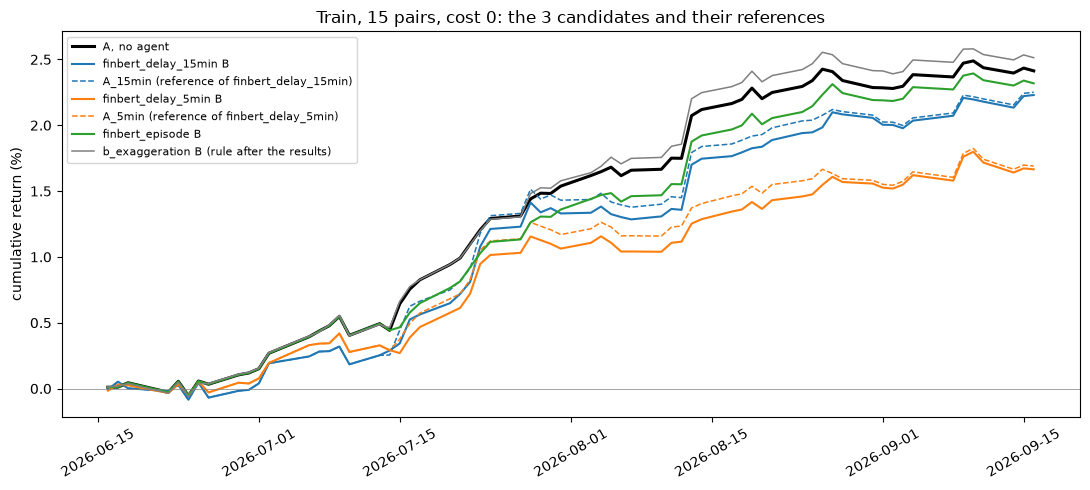

In [12]:
by_key = {(v.name, v.version): v for v in variants}
eq = lambda t: daily_pnl(add_costs(t, 0), days).equity * 100   # noqa: E731
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(days, eq(A), color="black", lw=2.2, label="A, no agent")
for color, key in zip(("tab:blue", "tab:orange", "tab:green"), candidates.index):
    v = by_key[key]
    ax.plot(days, eq(v.trades), color=color, lw=1.5, label=f"{v.name} {v.version}")
    if v.reference != "A":
        ax.plot(days, eq(ref[v.reference]), color=color, lw=1.1, ls="--", label=f"{v.reference} (reference of {v.name})")
ax.plot(days, eq(by_key[("b_exaggeration", "B")].trades), color="grey", lw=1.1, label="b_exaggeration B (rule after the results)")
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("cumulative return (%)")
ax.set_title("Train, 15 pairs, cost 0: the 3 candidates and their references")
ax.tick_params(axis="x", rotation=30)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "equity_curves.png", dpi=120)
plt.show()

## 6. Saving

Tables in `Results/`, trades and decisions of the decision sets in their folders in `Results/agent_variants/`, all on git.

In [13]:
tables = {"A_by_cost": by_cost(A, days), "A_by_pair": by_group(A, "pair", cost_bps=0), "trades_A": A, "version_comparison": cmp,
          "blocked_vs_random": evaluate_blocks(variants, ref), "news_right_C": evaluate_follows(variants, ref),
          "candidates": candidates, "B_and_C_by_variant": by_variant(cmp, evaluate_follows(variants, ref))}
for name in available_versions(complete=True):
    for letter, t in version_trades(trades, name).items():
        if letter != "A":
            tables[f"agent_variants/{name}/trades_{letter}"] = t
    copy = VERSIONS[name]["copy"]
    if not version_file(name)[1] and copy is not None and copy.name == "decisions.csv":
        tables[f"agent_variants/{name}/decisions"] = load_version(name)    # refreshes the copy on git from the original file
for p in save_results(tables):
    print(p.relative_to(RESULTS.parent))

Results/A_by_cost.csv
Results/A_by_pair.csv
Results/trades_A.csv
Results/version_comparison.csv
Results/blocked_vs_random.csv
Results/news_right_C.csv
Results/candidates.csv
Results/B_and_C_by_variant.csv
Results/agent_variants/spark_24h/trades_B.csv
Results/agent_variants/spark_24h/trades_C.csv
Results/agent_variants/spark_6h/trades_B.csv
Results/agent_variants/spark_6h/trades_C.csv
Results/agent_variants/spark_6h/decisions.csv
Results/agent_variants/lexicon/trades_B.csv
Results/agent_variants/lexicon/trades_C.csv
Results/agent_variants/lexicon/decisions.csv
Results/agent_variants/3b_6h/trades_B.csv
Results/agent_variants/finbert_session/trades_B.csv
Results/agent_variants/finbert_session/trades_C.csv
Results/agent_variants/c_fresh/trades_C.csv
Results/agent_variants/finbert_episode/trades_B.csv
Results/agent_variants/finbert_episode/trades_C.csv


## 7. What the results tell us

Numbers from the tables above: train, 15 pairs, 973 signals, cost 0 unless stated.

**Version A.** 973 trades with +7.44 gross basis points each: +7,239 dollars on 300,000 in 64 days (+2.4%). The trades that revert earn (+38.8 bps), and so do the entries in the overnight gap (11.4 bps against 3.9 after the first 30 minutes). Two pairs, PYPL-XYZ and CRM-WDAY, make almost half of the gross profit. Break-even is at 1.86 bps per operation: at 5 bps A loses 12,221 dollars. Waiting before entering costs: 2,168 dollars with 5 minutes, 487 with 15.

**Comparison.** No variant with the rule written beforehand beats its reference.
- At the top of the ranking is `c_fresh`, which however coincides with A: on the train it never finds a news item to follow.
- Next come the B with a delayed entry (-63 and -75 dollars relative to their delayed A) and `finbert_episode` B (-285).
- The B of `finbert_session` and `3b_6h` lose about 500 dollars; those of `spark_24h`, `spark_6h` and `lexicon` between 1,334 and 1,527.
- The C do worse than the B with the same decisions: down to -3,444 dollars.
- Halving the size instead of blocking limits the loss, but does not remove it.

The only one above A is `b_exaggeration` (+300 dollars), built by looking at precisely these results.

**Candidates for the test.** Excluding `b_exaggeration` (rule written after the results) and `c_fresh` (identical to A), the first 3 B are `finbert_delay_15min` (-63 $), `finbert_delay_5min` (-75 $) and `finbert_episode` (-285 $). The differences between them are within the noise (Step 7).

**Chosen variant: `finbert_episode`.** Only one variant goes to the test with its B and its C, so they are looked at together (table "B and C of the same variant"):
- it has the best C (-651 $, news right in 55% of the cases) and the best mean rank between B and C;
- it enters at the time of the signal, like A, so the A, B, C comparison on the test is direct. The delayed variants are instead compared with a delayed A, and the wait alone costs relative to A: 487 $ with 15 minutes, 2,168 $ with 5;
- on the B + C sum it is second behind `finbert_delay_5min`, by 73 $: that is noise.

The criterion (dollars at cost 0 relative to the reference, only rules written beforehand) was made precise after seeing the train, but before the test: the whole variant is chosen, with the same entry as A. It must be stated in the report.

**PYPL-XYZ.** The candidates lose relative to the reference almost only because of one block on PYPL-XYZ, on 15 July. The pair is not excluded:
- removing it after seeing the results would mean fitting the strategy to the train;
- it would also remove the pair that earns the most in A.

The dependence on this pair is stated in the report (Step 7).

**In short.** On the train no use of the news improves the strategy visibly. `finbert_episode` goes to the test, with A, B and C, only once.

**Limits.**
- Train only, on which signal and rules were chosen: optimistic results. With 21 variants tried, the best one is also the best by chance.
- Few blocks (4-166) and few `follow`s (0-61).
- Estimated costs, no stock borrowing cost.
- The models may know the events of the period (lookahead).
- The sets on the 40 signals of the sample are not here: on the sample the agent and the group took the same decision 38 times out of 40 (`Results/comparison_sample_40.csv`).